# <b>Task 3.3 - Advanced Validation Techniques.</b>

**Goal:** answer three questions from the assignment:
1. How to prove model A is statistically better than model B? What if there are N models?
2. What monitoring system is needed for live deployment?
3. Should we accept, reject, or observe? Justify.

**Methods:** pairwise DM matrix, Hansen SPA, Model Confidence Set, Romano-Wolf stepdown,
PSI feature drift, CUSUM, rolling Score monitors, killswitch rules.

**Inputs:** `data/enriched/btc_sub10.parquet`

## <b>Imports.</b>

In [1]:
import numpy as np
import polars as pl
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import utilities_score as us
import utilities_baselines as ub
import utilities_validation as uv
import utilities_multiple_testing as umt
import utilities_monitoring as umon

## <b>Load Data / Compute daily Score.</b>

In [2]:
# Path to data.
DATA_PATH = r"data/enriched/btc_sub10.parquet"

In [3]:
# Download data.
data = pl.read_parquet(DATA_PATH)

# Convert NaN -> Null in PnL columns for safe polars aggregation.
pnl_cols = [f"pnl_{t}s" for t in us.HORIZONS_S]

data = data.with_columns([
    pl.when(pl.col(c).is_nan()).then(None).otherwise(pl.col(c)).alias(c)
    for c in pnl_cols
])

n = data.shape[0]
print(f"Loaded: {n:,} trades")

Loaded: 80,403,526 trades


In [4]:
# define baselines to validate (from Phase 1).
BASELINES = {}

# random 30% - null hypothesis.
BASELINES["Random 30%"] = ub.random_filter(n, 0.3, seed=42)

# threshold baselines (same logic as Phase 1).
feature_configs = [
    ("vpin_5s",         "above", 0.70, "VPIN 5s (q=70%)"),
    ("dist_to_mid",     "above", 0.10, "Dist-to-mid above (q=10%)"),
    ("liq_binance_30s", "above", 0.10, "Liq Binance 30s (q=10%)"),
    ("liq_bybit_30s",   "above", 0.10, "Liq Bybit 30s (q=10%)"),
    ("obi",             "below", 0.90, "OBI (ask-heavy) (q=90%)")
]

for col_name, direction, quantile, label in feature_configs:
    values = ub.get_feature_array(data, col_name)
    valid  = values[~np.isnan(values)]
    thresh = float(np.quantile(valid, quantile))
    f_arr  = ub.threshold_filter(values, thresh, direction)
    BASELINES[label] = f_arr
    r = us.compute_score(data, f_arr, tau=30)
    print(f"{label:<30s}  Score_30={r.score:+.4f}  filter={r.filter_rate:.1%}")

print(f"\nTotal baselines: {len(BASELINES)}")

VPIN 5s (q=70%)                 Score_30=+0.0368  filter=30.0%
Dist-to-mid above (q=10%)       Score_30=+0.6468  filter=90.0%
Liq Binance 30s (q=10%)         Score_30=+0.5065  filter=90.0%
Liq Bybit 30s (q=10%)           Score_30=+0.4392  filter=90.0%
OBI (ask-heavy) (q=90%)         Score_30=+0.0589  filter=90.0%

Total baselines: 6


In [5]:
# daily Scores.
TAU = 30
daily_scores = {}
for label, f_arr in BASELINES.items():
    df_d = us.compute_daily_scores(data, f_arr, tau=TAU)
    daily_scores[label] = df_d["score"].to_numpy().astype(np.float64)

n_days = len(daily_scores["Random 30%"])
print(f"Baselines: {len(BASELINES)}, days: {n_days}")

Baselines: 6, days: 179


## <b>Block A - Pairwise model comparison.</b>

Question: "How can you tell model A is statistically better than model B?"

Answer: Diebold-Mariano test with HAC variance on daily Score differences.
We compute the **full NxN matrix** of pairwise comparisons.

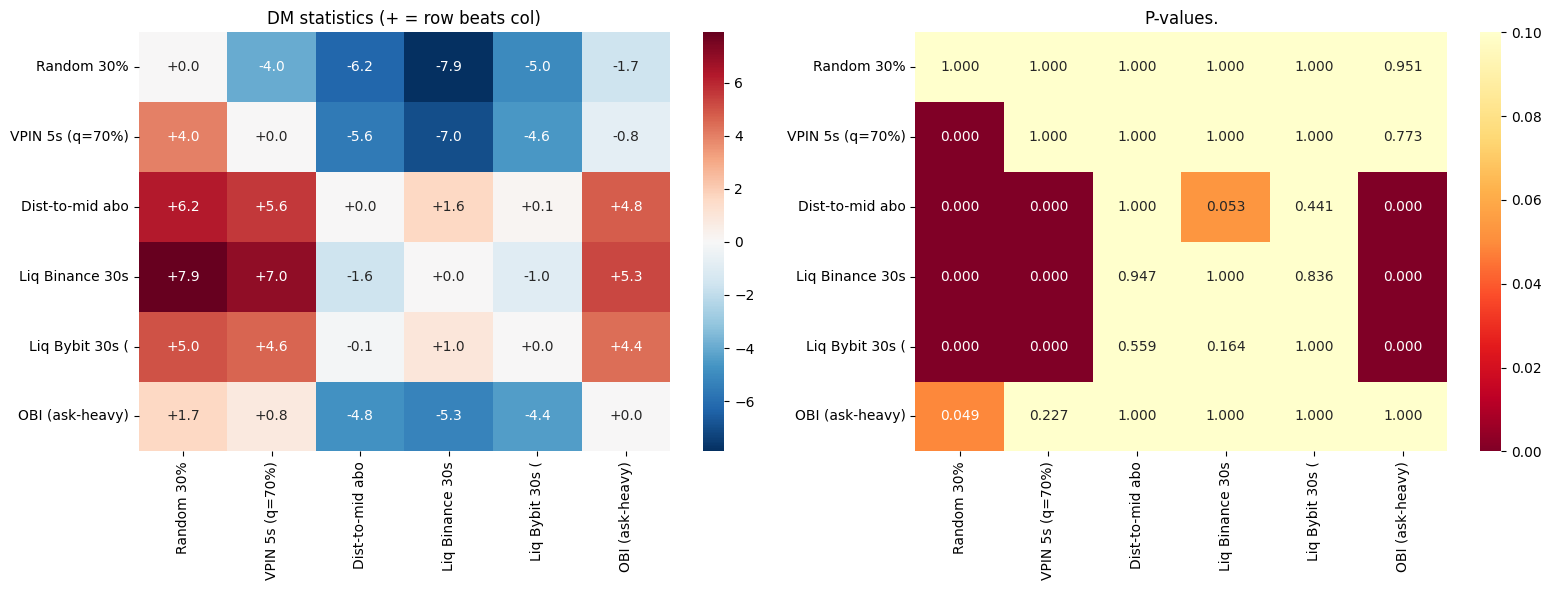

In [6]:
# compute statistics.
names, dm_stats, p_values = umt.pairwise_dm_matrix(daily_scores)

# plot heatmap.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

short_names = [n[:15] for n in names]

sns.heatmap(dm_stats, xticklabels=short_names, yticklabels=short_names, annot=True, fmt="+.1f", cmap="RdBu_r", center=0, ax=axes[0])
axes[0].set_title("DM statistics (+ = row beats col)")

sns.heatmap(p_values, xticklabels=short_names, yticklabels=short_names, annot=True, fmt=".3f", cmap="YlOrRd_r", vmin=0, vmax=0.1, ax=axes[1])
axes[1].set_title("P-values.")

plt.tight_layout()
plt.show()

## <b>Block B - Multiple testing corrections.</b>

Question: "What if you have N models? Can we choose one that's superior?"

Three methods of increasing power:
1. **Hansen SPA** - is the best filter genuinely better than Random?
2. **Model Confidence Set** - which filters are indistinguishable from the best?
3. **Romano-Wolf stepdown** - which individual filters beat Random after FWER correction?

### <b>B.1. Hansen SPA.</b>

Among all the filters tested, is there at least one that is actually 30% better than Random, or could the best result have simply been due to exhaustive testing?

In [7]:
# Hansen SPA.
print("Hansen SPA test")
print("H0: no filter is better than Random 30%")
print("H1: at least one filter is genuinely better\n")

spa = umt.hansen_spa_test(daily_scores, benchmark_name="Random 30%", n_boot=5000)
print(f"  Test statistic:  {spa.test_stat:+.4f}")
print(f"  p-value:         {spa.p_value:.4f}")
print(f"  Reject H0:       {'YES' if spa.reject_h0 else 'no'}")
print(f"  Best filter:     {spa.best_filter}")
print(f"  Best mean diff:  {spa.best_mean_diff:+.6f} bps/day")

if spa.reject_h0:
    print("\n At least one filter is genuinely superior to Random.")
    print(" The result is robust to data-snooping correction within the tested set of candidate filters.")
else:
    print("\n Cannot reject that all filters are no better than Random.")

Hansen SPA test
H0: no filter is better than Random 30%
H1: at least one filter is genuinely better

  Test statistic:  +7.8964
  p-value:         0.0000
  Reject H0:       YES
  Best filter:     Liq Binance 30s (q=10%)
  Best mean diff:  +0.428508 bps/day

 At least one filter is genuinely superior to Random.
 The result is robust to data-snooping correction within the tested set of candidate filters.


### <b>B.2. Model Confidence Set, MCS.</b>

Is it possible to objectively choose a single best filter, or are several filters statistically indistinguishable from one another?

In other words, after the SPA test, we already know :
- that having at least one filter is 30% better than using Random.

And MCS answers the following question: 
- Which specific filters are among the best?

In [8]:
# Model Confidence Set.
print("Model Confidence Set (MCS)")
print("Iteratively eliminates the worst model until remaining models are statistically indistinguishable.\n")

mcs = umt.model_confidence_set(daily_scores, n_boot=5000, alpha=0.05)

print(f"Confidence set (alpha=0.05):")
for name in mcs.confidence_set:
    print(f" {name}")

print(f"\nEliminated:")
for name in mcs.eliminated:
    p = mcs.elimination_pvals.get(name, None)
    print(f" {name}  (p={p})")

print(f"\nThe MCS contains {len(mcs.confidence_set)} filters.")
print("  These are 'equally best' - we cannot distinguish between them at the 5% significance level.")

Model Confidence Set (MCS)
Iteratively eliminates the worst model until remaining models are statistically indistinguishable.

Confidence set (alpha=0.05):
 Dist-to-mid above (q=10%)
 Liq Binance 30s (q=10%)
 Liq Bybit 30s (q=10%)

Eliminated:
 Random 30%  (p=0.0)
 VPIN 5s (q=70%)  (p=0.0)
 OBI (ask-heavy) (q=90%)  (p=0.0)

The MCS contains 3 filters.
  These are 'equally best' - we cannot distinguish between them at the 5% significance level.


### <b>B.3. Romano - Wolf stepdown procedure.</b>

Which filters are statistically significantly better than Random 30% if we test many filters at the same time?

In [9]:
# Romano-Wolf stepdown.
print("Romano-Wolf stepdown (FWER control)")
print("H0_k: filter k is no better than Random 30%")
print("Controls FWER at 5% across all simultaneous tests.\n")

rw = umt.romano_wolf_stepdown(daily_scores, benchmark_name="Random 30%", n_boot=5000)

print("Rejected (significantly better than Random, after FWER correction):")
for name in rw.rejected:
    print(f" {name}  (adj. p = {rw.adjusted_pvalues[name]})")

print("\nNot rejected:")
for name in rw.not_rejected:
    print(f"  {name}  (adj. p = {rw.adjusted_pvalues[name]})")

print(f"\n{len(rw.rejected)} out of {len(rw.rejected) + len(rw.not_rejected)} filters survive FWER correction.")

Romano-Wolf stepdown (FWER control)
H0_k: filter k is no better than Random 30%
Controls FWER at 5% across all simultaneous tests.

Rejected (significantly better than Random, after FWER correction):
 Liq Binance 30s (q=10%)  (adj. p = 0.0)
 Dist-to-mid above (q=10%)  (adj. p = 0.0)
 Liq Bybit 30s (q=10%)  (adj. p = 0.0)
 VPIN 5s (q=70%)  (adj. p = 0.0)
 OBI (ask-heavy) (q=90%)  (adj. p = 0.0414)

Not rejected:

5 out of 5 filters survive FWER correction.


## <b>Block C - Audit for hidden leakage.</b>

**Look-ahead in thresholds:** full-sample quantiles vs expanding-window.

In [11]:
print("Look-ahead audit: full-sample vs expanding-window thresholds")

US_PER_DAY = us.US_PER_DAY
WARMUP_DAYS = 60
TAU = 30

ts = data["timestamp"].to_numpy()
day_ids = ts // US_PER_DAY
unique_days = np.sort(np.unique(day_ids))

# Start position and length of each day in the dataframe.
unique_days_ordered, day_start_idx, day_counts = np.unique(
    day_ids,
    return_index=True,
    return_counts=True
)

day_end_idx = day_start_idx + day_counts


def extract_score(result):
    """
    us.compute_score may return either a scalar or an object with .score.
    This helper makes the code robust to both cases.
    """
    return float(result.score) if hasattr(result, "score") else float(result)


def apply_threshold_array(values, thresholds, direction):
    """
    Apply row-wise thresholds.
    thresholds[i] is the threshold available for observation i.
    """
    valid = np.isfinite(values) & np.isfinite(thresholds)

    if direction == "above":
        return valid & (values >= thresholds)

    if direction == "below":
        return valid & (values <= thresholds)

    raise ValueError(f"Unknown direction: {direction}")


def expanding_threshold_by_day(values, q, warmup_days):
    """
    For each day after the warmup period, compute the threshold using only
    observations from previous days.

    For day d:
        threshold_d = quantile(values from days < d, q)
    """
    thresholds = np.full(values.shape, np.nan, dtype=float)

    for day_pos in range(warmup_days, len(unique_days_ordered)):

        current_start = day_start_idx[day_pos]
        current_end = day_end_idx[day_pos]

        past_values = values[:current_start]
        threshold = float(np.nanquantile(past_values, q))

        thresholds[current_start:current_end] = threshold

    return thresholds


# Format: feature, direction, quantile, label.
lookahead_configs = [
    ("vpin_5s",          "above", 0.70, "VPIN 5s (q=70%)"),
    ("dist_to_mid",      "above", 0.10, "Dist-to-mid above (q=10%)"),
    ("liq_binance_30s",  "above", 0.10, "Liq Binance 30s (q=10%)"),
    ("liq_bybit_30s",    "above", 0.10, "Liq Bybit 30s (q=10%)"),
    ("obi",             "below", 0.90, "OBI ask-heavy (q=90%)"),
]

audit_rows = []

for col, direction, q, label in lookahead_configs:

    values_full = ub.get_feature_array(data, col)

    # 1. Full-sample threshold.
    full_threshold = float(np.nanquantile(values_full, q))

    # 2. Expanding-window threshold.
    expanding_thresholds = expanding_threshold_by_day(
        values=values_full,
        q=q,
        warmup_days=WARMUP_DAYS
    )

    # 3. Compare only post-warmup observations.
    post_warmup_mask = np.isfinite(expanding_thresholds)

    data_post = data.filter(pl.Series(post_warmup_mask))
    values_post = values_full[post_warmup_mask]
    expanding_thresholds_post = expanding_thresholds[post_warmup_mask]

    # 4. Apply full-sample threshold on post-warmup data.
    f_full = ub.threshold_filter(
        values_post,
        full_threshold,
        direction
    )

    # 5. Apply expanding-window threshold on post-warmup data.
    f_expanding = apply_threshold_array(
        values=values_post,
        thresholds=expanding_thresholds_post,
        direction=direction
    )

    # 6. Compute scores.
    r_full = us.compute_score(
        data_post,
        f_full,
        tau=TAU
    )

    r_expanding = us.compute_score(
        data_post,
        f_expanding,
        tau=TAU
    )

    score_full = extract_score(r_full)
    score_expanding = extract_score(r_expanding)

    # 7. Difference and relative deflation.
    score_diff = score_full - score_expanding
    abs_score_diff = abs(score_diff)

    MIN_SCORE_FOR_RELATIVE = 0.01

    if abs(score_full) >= MIN_SCORE_FOR_RELATIVE:
        deflation_pct = 100.0 * score_diff / abs(score_full)
    else:
        deflation_pct = np.nan

    # 8. Verdict.
    if abs(score_full) < MIN_SCORE_FOR_RELATIVE and abs(score_expanding) < MIN_SCORE_FOR_RELATIVE:
        verdict = "weak signal"
    elif np.isnan(deflation_pct):
        verdict = "not informative"
    elif deflation_pct < -10:
        verdict = "expanding better"
    elif abs(deflation_pct) < 10:
        verdict = "stable"
    elif abs(deflation_pct) < 30:
        verdict = "moderate inflation"
    else:
        verdict = "material look-ahead risk"

    # 9. Save row.
    audit_rows.append({
        "filter": label,
        "feature": col,
        "direction": direction,
        "quantile": q,
        "warmup_days": WARMUP_DAYS,
        "full_threshold": full_threshold,
        "last_expanding_threshold": float(expanding_thresholds_post[-1]),
        "full_score_30": score_full,
        "expanding_score_30": score_expanding,
        "score_diff": score_diff,
        "abs_score_diff": abs_score_diff,
        "deflation_pct": deflation_pct,
        "verdict": verdict,
    })


lookahead_audit = pd.DataFrame(audit_rows)

if lookahead_audit.empty:
    raise ValueError("lookahead_audit is empty: no rows were added to audit_rows.")

# Pretty formatting for display.
lookahead_audit_display = lookahead_audit.copy()

round_cols = [
    "quantile",
    "full_threshold",
    "last_expanding_threshold",
    "full_score_30",
    "expanding_score_30",
    "score_diff",
    "abs_score_diff",
    "deflation_pct",
]

for col in round_cols:
    lookahead_audit_display[col] = pd.to_numeric(
        lookahead_audit_display[col],
        errors="coerce"
    ).round(4)

display(lookahead_audit_display)

Look-ahead audit: full-sample vs expanding-window thresholds


,filter,feature,direction,quantile,warmup_days,full_threshold,last_expanding_threshold,full_score_30,expanding_score_30,score_diff,abs_score_diff,deflation_pct,verdict
0,VPIN 5s (q=70%),vpin_5s,above,0.7,60,0.6997,0.6993,0.0448,0.0448,-0.0000,0.0000,-0.0380,stable
1,Dist-to-mid above (q=10%),dist_to_mid,above,0.1,60,-0.6800,-0.6804,0.5528,0.5274,0.0254,0.0254,4.5968,stable
2,Liq Binance 30s (q=10%),liq_binance_30s,above,0.1,60,-0.1200,-0.1200,0.3862,0.3823,0.0039,0.0039,1.0127,stable
3,Liq Bybit 30s (q=10%),liq_bybit_30s,above,0.1,60,-0.0460,-0.0470,0.4232,0.4303,-0.0071,0.0071,-1.6761,stable
4,OBI ask-heavy (q=90%),obi,below,0.9,60,0.9933,0.9934,-0.0037,-0.0110,0.0073,0.0073,NaN,not informative


## <b>Block D - Monitoring system for live deployment.</b>

Question: "If deployed live tomorrow, what monitoring would you require?"

Four layers:
1. **Feature drift (PSI)** - detect when market regime changes inputs.
2. **Score drift (CUSUM)** - detect gradual degradation.
3. **Rolling Score with bands** - detect sudden performance change.
4. **Killswitch** - automated stop rules.

### <b>D.1. Population Stabiity Index (PSI).</b>

In [12]:
# PSI: train vs val feature distributions.
# Split at roughly 2/3 mark, matching original train/val split.

TRAIN_END_DAY = 120
TOP_N_DRIFT_FEATURES = 4

ts = data["timestamp"].to_numpy()
day_ids = ts // US_PER_DAY
unique_days = np.sort(np.unique(day_ids))
split_day = unique_days[min(TRAIN_END_DAY, len(unique_days) - 1)]

train_mask = day_ids <= split_day
val_mask   = day_ids > split_day

feature_cols = [
    "vpin_5s", "vpin_30s", "vpin_120s",
    "rv_5s", "rv_30s", "rv_120s",
    "spread", "obi", "dist_to_mid",
    "liq_binance_30s", "liq_bybit_30s",
]

train_features = {c: data[c].to_numpy()[train_mask] for c in feature_cols}
val_features   = {c: data[c].to_numpy()[val_mask]   for c in feature_cols}

psi_values = umon.compute_psi_matrix(train_features, val_features)

# Build PSI table.
psi_df = pd.DataFrame([
    {
        "feature": feat,
        "psi": psi,
        "verdict": umon.psi_verdict(psi),
    }
    for feat, psi in psi_values.items()
])

psi_df = psi_df.sort_values("psi", ascending=False).reset_index(drop=True)

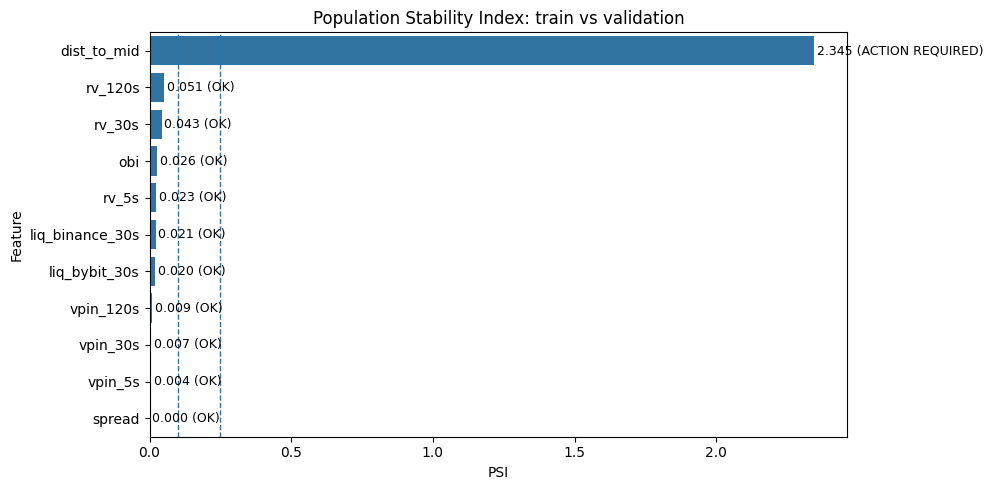

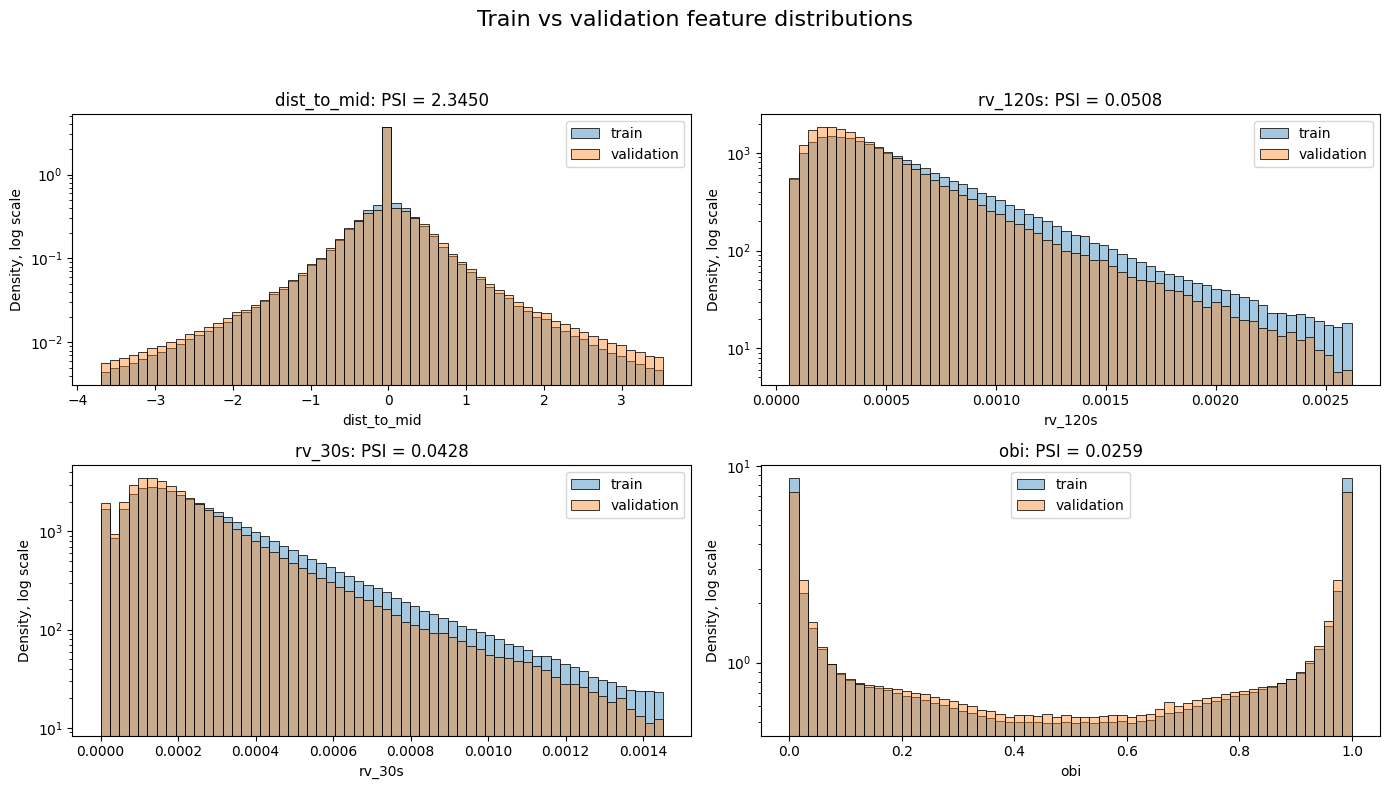

In [13]:
# Plot PSI values.
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(data=psi_df, x="psi", y="feature", ax=ax)

ax.axvline(0.10, linestyle="--", linewidth=1)
ax.axvline(0.25, linestyle="--", linewidth=1)

ax.set_title("Population Stability Index: train vs validation")
ax.set_xlabel("PSI")
ax.set_ylabel("Feature")

# Add labels.
for i, row in psi_df.iterrows():
    ax.text(
        row["psi"] + 0.01,
        i,
        f"{row['psi']:.3f} ({row['verdict']})",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()


# Plot train vs validation distributions for top drifted features.
top_features = psi_df.head(TOP_N_DRIFT_FEATURES)["feature"].tolist()

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.ravel()

for i, feat in enumerate(top_features):
    ax = axes[i]

    x_train = train_features[feat]
    x_val = val_features[feat]

    x_train = x_train[np.isfinite(x_train)]
    x_val = x_val[np.isfinite(x_val)]

    # Clip extreme tails for readability.
    combined = np.concatenate([x_train, x_val])
    lo, hi = np.nanpercentile(combined, [1, 99])

    x_train_plot = x_train[(x_train >= lo) & (x_train <= hi)]
    x_val_plot = x_val[(x_val >= lo) & (x_val <= hi)]

    sns.histplot(x_train_plot, bins=60, stat="density", alpha=0.4, label="train", ax=ax)
    sns.histplot(x_val_plot, bins=60, stat="density", alpha=0.4, label="validation", ax=ax)

    ax.set_yscale("log")

    ax.set_title(f"{feat}: PSI = {psi_values[feat]:.4f}")
    ax.set_xlabel(feat)
    ax.set_ylabel("Density, log scale")
    ax.legend()

# Hide unused axes if TOP_N_DRIFT_FEATURES < 4.
for j in range(len(top_features), len(axes)):
    axes[j].axis("off")

fig.suptitle("Train vs validation feature distributions", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

### <b>D.2 / D.3: CUSUM and Rolling Window.</b> 

CUSUM and rolling monitor for 'Dist-to-mid above (q=10%)'
Train mean: +0.6650
CUSUM threshold H: 4.3499
Positive CUSUM alarms: 1 at days [50]
Negative CUSUM alarms: 0 at days []
Rolling breaches above: 0
Rolling breaches below: 0


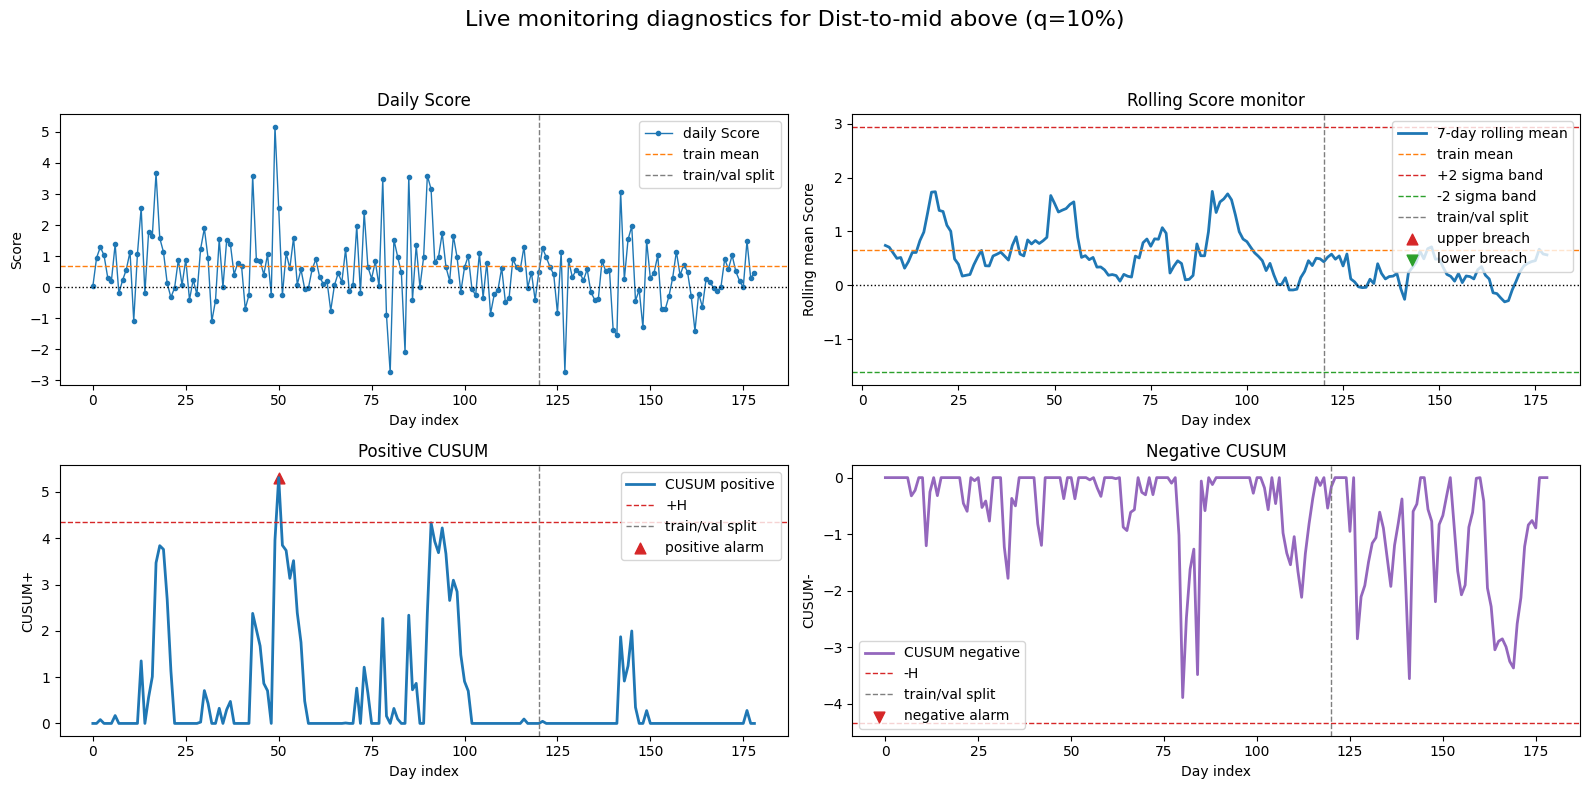

In [14]:
# CUSUM and rolling monitoring for the best filter.

best_label = "Dist-to-mid above (q=10%)"
best_daily = daily_scores[best_label]

WINDOW = 7

# Target mean from train period.
train_score_mean = best_daily[:TRAIN_END_DAY].mean()

# CUSUM monitor.
cusum = umon.cusum_chart(best_daily, target_mean=train_score_mean)

# Rolling score monitor.
rolling = umon.rolling_score_monitor(
    daily_scores_train  = best_daily[:TRAIN_END_DAY],
    daily_scores_full   = best_daily,
    window              = WINDOW,
    n_sigma             = 2.0
)

print(f"CUSUM and rolling monitor for '{best_label}'")
print(f"Train mean: {train_score_mean:+.4f}")
print(f"CUSUM threshold H: {cusum.threshold:.4f}")
print(f"Positive CUSUM alarms: {len(cusum.alarms_pos)} at days {cusum.alarms_pos}")
print(f"Negative CUSUM alarms: {len(cusum.alarms_neg)} at days {cusum.alarms_neg}")
print(f"Rolling breaches above: {len(rolling.breaches_above)}")
print(f"Rolling breaches below: {len(rolling.breaches_below)}")

days = np.arange(len(best_daily))

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
axes = axes.ravel()

# 1. Raw daily Score.
ax = axes[0]
ax.plot(days, best_daily, marker="o", markersize=3, linewidth=1, color="tab:blue", label="daily Score")
ax.axhline(train_score_mean, linestyle="--", linewidth=1, color="tab:orange", label="train mean")
ax.axvline(TRAIN_END_DAY, linestyle="--", linewidth=1, color="tab:gray", label="train/val split")
ax.axhline(0, linestyle=":", linewidth=1, color="black")
ax.set_title("Daily Score")
ax.set_xlabel("Day index")
ax.set_ylabel("Score")
ax.legend()

# 2. Rolling Score.
ax = axes[1]
ax.plot(days, rolling.rolling_mean, linewidth=2, color="tab:blue", label=f"{WINDOW}-day rolling mean")
ax.axhline(rolling.center, linestyle="--", linewidth=1, color="tab:orange", label="train mean")
ax.axhline(rolling.upper_band, linestyle="--", linewidth=1, color="tab:red", label="+2 sigma band")
ax.axhline(rolling.lower_band, linestyle="--", linewidth=1, color="tab:green", label="-2 sigma band")
ax.axvline(TRAIN_END_DAY, linestyle="--", linewidth=1, color="tab:gray", label="train/val split")
ax.axhline(0, linestyle=":", linewidth=1, color="black")
ax.scatter(rolling.breaches_above, rolling.rolling_mean[rolling.breaches_above], marker="^", s=60, color="tab:red", label="upper breach")
ax.scatter(rolling.breaches_below, rolling.rolling_mean[rolling.breaches_below], marker="v", s=60, color="tab:green", label="lower breach")
ax.set_title("Rolling Score monitor")
ax.set_xlabel("Day index")
ax.set_ylabel("Rolling mean Score")
ax.legend()

# 3. Positive CUSUM.
ax = axes[2]
ax.plot(days, cusum.cusum_pos, linewidth=2, color="tab:blue", label="CUSUM positive")
ax.axhline(cusum.threshold, linestyle="--", linewidth=1, color="tab:red", label="+H")
ax.axvline(TRAIN_END_DAY, linestyle="--", linewidth=1, color="tab:gray", label="train/val split")
ax.scatter(cusum.alarms_pos, cusum.cusum_pos[cusum.alarms_pos], marker="^", s=60, color="tab:red", label="positive alarm")
ax.set_title("Positive CUSUM")
ax.set_xlabel("Day index")
ax.set_ylabel("CUSUM+")
ax.legend()

# 4. Negative CUSUM.
ax = axes[3]
ax.plot(days, cusum.cusum_neg, linewidth=2, color="tab:purple", label="CUSUM negative")
ax.axhline(-cusum.threshold, linestyle="--", linewidth=1, color="tab:red", label="-H")
ax.axvline(TRAIN_END_DAY, linestyle="--", linewidth=1, color="tab:gray", label="train/val split")
ax.scatter(cusum.alarms_neg, cusum.cusum_neg[cusum.alarms_neg], marker="v", s=60, color="tab:red", label="negative alarm")
ax.set_title("Negative CUSUM")
ax.set_xlabel("Day index")
ax.set_ylabel("CUSUM-")
ax.legend()

fig.suptitle(f"Live monitoring diagnostics for {best_label}", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

### <b>D.4. Killswitch.</b>

In [16]:
# Killswitch evaluation on validation period.

val_daily = best_daily[TRAIN_END_DAY:]

# Compute turnover on validation period only (not global).
ts = data["timestamp"].to_numpy()
day_ids = ts // us.US_PER_DAY
unique_days = np.sort(np.unique(day_ids))
split_day = unique_days[min(TRAIN_END_DAY, len(unique_days) - 1)]

val_mask = day_ids > split_day
data_val = data.filter(pl.Series(val_mask))
f_val = BASELINES[best_label][val_mask]

r_val = us.compute_score(data_val, f_val, tau=30)

ks = umon.evaluate_killswitch(
    daily_scores_recent     = val_daily,
    psi_values              = psi_values,
    kept_turnover_per_day   = r_val.kept_turnover_per_day,
)

# Summary table.
killswitch_summary = pd.DataFrame([
    {
        "filter": best_label,
        "period": "validation",
        "triggered": ks.triggered,
        "consecutive_negative_days": ks.consecutive_neg_days,
        "max_psi": ks.max_psi,
        "max_psi_feature": ks.max_psi_feature,
        "turnover_ok": ks.turnover_ok,
        "kept_turnover_per_day": r_val.kept_turnover_per_day,
        "decision": "recalibrate / do not deploy as-is" if ks.triggered else "pass",
    }
])

display(killswitch_summary)

,filter,period,triggered,consecutive_negative_days,max_psi,max_psi_feature,turnover_ok,kept_turnover_per_day,decision
0,Dist-to-mid above (q=10%),validation,True,4,2.345,dist_to_mid,True,1.332175e+08,recalibrate / do not deploy as-is
